In [7]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Liczba obrazów treningowych:", len(train_dataset))
print("Liczba obrazów testowych:", len(test_dataset))

100%|██████████| 170M/170M [07:58<00:00, 356kB/s]


Liczba obrazów treningowych: 50000
Liczba obrazów testowych: 10000


In [8]:
from torch.utils.data import DataLoader

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=False, transform=train_transform
)
test_dataset = datasets.CIFAR10(
    root="./data", train=False, download=False, transform=test_transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print(images.shape, labels.shape, images.mean().item(), images.std().item())

torch.Size([128, 3, 32, 32]) torch.Size([128]) -0.23165149986743927 1.1531521081924438


In [9]:
import torch
import torch.nn as nn

class HighwayConv(nn.Module):
    def __init__(self, channels, gate_bias=-1.0):
        super().__init__()
        # H(x): conv + ReLU
        self.conv_h = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        # T(x): transform gate
        self.conv_t = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        nn.init.constant_(self.conv_t.bias, gate_bias)

    def forward(self, x):
        h = torch.relu(self.conv_h(x))
        t = torch.sigmoid(self.conv_t(x))
        return h * t + x * (1 - t)

In [10]:
block = HighwayConv(16)
x = torch.randn(4, 16, 32, 32)
y = block(x)
print(y.shape)

torch.Size([4, 16, 32, 32])


In [11]:
class HighwayNet(nn.Module):
    def __init__(self, channels=64, num_blocks=8, num_classes=10, gate_bias=-1.0):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

        warstwy = []
        for i in range(num_blocks):
            warstwy.append(HighwayConv(channels, gate_bias=gate_bias))
        self.highway = nn.Sequential(*warstwy)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(channels, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.highway(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = HighwayNet(channels=64, num_blocks=8, gate_bias=-1.0).to(device)

print(device)
print("Params:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

images, labels = next(iter(train_loader))
logits = model(images.to(device))
print(logits.shape)

cuda
Params: 0.59329 M
torch.Size([128, 10])


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)

EPOCHS = 85
history_train, history_test = [], []
history_train_loss, history_test_loss = [], []
best_acc = 0.0

for epoch in range(1, EPOCHS + 1):

    model.train()
    train_loss, train_correct, train_n = 0.0, 0, 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_n += images.size(0)

    model.eval()
    test_loss, test_correct, test_n = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)

            test_loss += loss.item() * images.size(0)
            test_correct += (logits.argmax(1) == labels).sum().item()
            test_n += images.size(0)

    tr_acc = 100 * train_correct / train_n
    te_acc = 100 * test_correct / test_n
    tr_loss = train_loss / train_n
    te_loss = test_loss / test_n

    history_train.append(tr_acc)
    history_test.append(te_acc)
    history_train_loss.append(tr_loss)
    history_test_loss.append(te_loss)

    if te_acc > best_acc:
        best_acc = te_acc
        torch.save(model.state_dict(), "highway_best.pt")

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {tr_loss:.3f} acc {tr_acc:.1f}% | "
        f"test loss {te_loss:.3f} acc {te_acc:.1f}%"
    )



Epoch 01/85 | train loss 2.034 acc 22.5% | test loss 1.867 acc 26.9%
Epoch 02/85 | train loss 1.679 acc 36.1% | test loss 1.679 acc 39.0%
Epoch 03/85 | train loss 1.477 acc 45.2% | test loss 1.440 acc 46.4%
Epoch 04/85 | train loss 1.324 acc 51.9% | test loss 1.221 acc 55.7%
Epoch 05/85 | train loss 1.210 acc 56.2% | test loss 1.159 acc 58.4%
Epoch 06/85 | train loss 1.129 acc 59.7% | test loss 1.271 acc 56.7%
Epoch 07/85 | train loss 1.067 acc 62.1% | test loss 1.011 acc 63.9%
Epoch 08/85 | train loss 1.007 acc 64.3% | test loss 1.012 acc 63.6%
Epoch 09/85 | train loss 0.952 acc 66.5% | test loss 0.998 acc 66.6%
Epoch 10/85 | train loss 0.906 acc 67.9% | test loss 0.988 acc 64.9%
Epoch 11/85 | train loss 0.875 acc 69.2% | test loss 0.861 acc 69.5%
Epoch 12/85 | train loss 0.842 acc 70.4% | test loss 0.828 acc 71.0%
Epoch 13/85 | train loss 0.822 acc 71.1% | test loss 0.815 acc 72.4%
Epoch 14/85 | train loss 0.809 acc 71.7% | test loss 0.837 acc 70.1%
Epoch 15/85 | train loss 0.790 acc

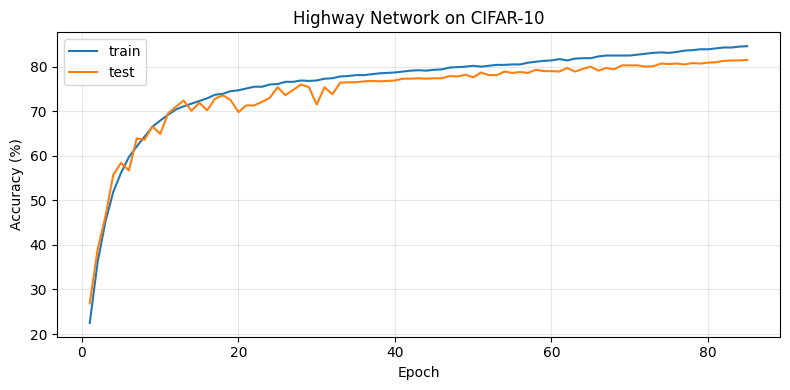

Best test accuracy: 81.5 %


In [5]:
import matplotlib.pyplot as plt

epochs = range(1, len(history_train) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, history_train, label="train")
plt.plot(epochs, history_test, label="test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Highway Network on CIFAR-10")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("highway_acc.png", dpi=150)
plt.show()

print("Best test accuracy:", max(history_test), "%")